# Лабораторная работа №1
## Линейная регрессия и факторный анализ

**Дисциплина:** Системы искусственного интеллекта и машинное обучение  
**Датасет:** Water Potability — пригодность воды для питья  
**Выполнил:** Гладышев Р.М. 
**Проверил:** Антонянц Е.Н. 

---

### Содержание
1. Введение
2. Описание датасета
3. Подготовка данных
4. Ход работы
5. Заключение
6. Список источников
7. Приложение

## 1. Введение

Цель работы — изучить основы линейной регрессии, построить простейшие регрессионные модели, обучить их на реальных данных и оценить качество.

Задачи:
1. Загрузить датасет, выполнить первичный анализ и визуализировать распределения признаков и целевой переменной.
2. Выполнить предобработку: удалить пропуски, при необходимости закодировать категориальные переменные, стандартизовать признаки.
3. Построить матрицу корреляций и оценить мультиколлинеарность с помощью VIF.
4. Построить модели (линейная, лассо, гребневая; для категориальной цели — логистическая регрессия) с разбиением на обучающую и тестовую выборки и кросс-валидацией; оценить их по RMSE, R² и MAPE.
5. Снизить размерность методом главных компонент (PCA) после стандартизации, повторить п. 4 на главных компонентах и сравнить метрики.


### Принятые методические решения

Целевая переменная Potability бинарная (0 — непитьевая, 1 — питьевая), поэтому, основной моделью выбрана логистическая регрессия в трёх вариантах: без регуляризации, с L1-штрафом (аналог Lasso) и с L2-штрафом (аналог Ridge). Чтобы выполнить пункт задания буквально, линейная регрессия, Lasso и Ridge дополнительно обучены на целевой переменной, закодированной как 0/1 (т. н. линейная вероятностная модель).

Метрики RMSE, R² и MAPE рассчитаны по предсказанным вероятностям класса 1 (для линейных моделей — по их выходу). Это накладывает ограничения:

* $\text{RMSE}^2$ в этом случае совпадает с оценкой Брайера (Brier score);
* MAPE не определён для объектов класса 0 (деление на ноль), поэтому он считается только по объектам класса 1.

Защита от утечки данных. Стандартизация и PCA обучаются только на обучающей части данных: они помещены внутрь Pipeline и поэтому внутри кросс-валидации видят лишь обучающие блоки. Это важно: подгонка StandardScaler/PCA на всей выборке до разбиения завышает оценку качества.

### Краткая теория

* Линейная регрессия (МНК): $\hat y = w_0 + \sum_j w_j x_j$, веса минимизируют $\sum_i (y_i-\hat y_i)^2$.
* Ridge (гребневая): к функции потерь добавляется $\alpha \sum_j w_j^2$ (L2-штраф), веса сжимаются, но не обнуляются.
* Lasso: добавляется $\alpha \sum_j |w_j|$ (L1-штраф); часть весов обнуляется — встроенный отбор признаков.
* Логистическая регрессия: $P(y=1\mid x)=\sigma(w_0+\sum_j w_j x_j)$; штрафы L1/L2 задаются коэффициентом $C = 1/\alpha$ (чем меньше $C$, тем сильнее регуляризация).
* VIF: $\text{VIF}_j = \dfrac{1}{1-R_j^2}$, где $R_j^2$ — коэффициент детерминации регрессии признака $j$ на остальные признаки. Ориентиры: < 5 — норма, 5–10 — умеренная, > 10 — сильная мультиколлинеарность.
* Метрики: $\text{RMSE}=\sqrt{\frac1n\sum(y_i-\hat y_i)^2}$, $\;R^2=1-\dfrac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$, $\;\text{MAPE}=\frac1n\sum\left|\dfrac{y_i-\hat y_i}{y_i}\right|$.
* PCA: ортогональное преобразование стандартизованных признаков в некоррелированные главные компоненты, упорядоченные по доле объяснённой дисперсии (собственным значениям ковариационной матрицы).

## 2. Описание датасета

Датасет содержит результаты измерений качества воды для 3276 водных объектов. Описание признаков:

| Признак | Смысл |
|---|---|
| ph | кислотно-щелочной баланс (норма ВОЗ: 6,5–8,5) |
| Hardness | жёсткость (соли кальция и магния) |
| Solids | общее содержание растворённых твёрдых веществ (TDS) |
| Chloramines | хлорамины (дезинфицирующие вещества) |
| Sulfate | сульфаты |
| Conductivity | электропроводность |
| Organic_carbon | общий органический углерод |
| Trihalomethanes | тригалометаны (побочные продукты хлорирования) |
| Turbidity | мутность |
| Potability | целевая переменная: 1 — питьевая, 0 — непитьевая |

[Источник датасета](https://www.kaggle.com/datasets/adityakadiwal/water-potability).

In [29]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Lasso, LogisticRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


warnings.filterwarnings("ignore", message="Setting penalty=None")

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
pd.set_option("display.width", 200)

print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.9.1


In [30]:
df = pd.read_csv("water_potability.csv")
print("Размер датасета (строк, столбцов):", df.shape)
df.head()

Размер датасета (строк, столбцов): (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.8905,20791.3190,7.3002,368.5164,564.3087,10.3798,86.9910,2.9631,0
1,3.7161,129.4229,18630.0579,6.6352,NaN,592.8854,15.1800,56.3291,4.5007,0
2,8.0991,224.2363,19909.5417,9.2759,NaN,418.6062,16.8686,66.4201,3.0559,0
3,8.3168,214.3734,22018.4174,8.0593,356.8861,363.2665,18.4365,100.3417,4.6288,0
4,9.0922,181.1015,17978.9863,6.5466,310.1357,398.4108,11.5583,31.9980,4.0751,0


In [31]:
df.info()
print()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB



,count,mean,std,min,25%,50%,75%,max
ph,2785.0000,7.0808,1.5943,0.0000,6.0931,7.0368,8.0621,14.0000
Hardness,3276.0000,196.3695,32.8798,47.4320,176.8505,196.9676,216.6675,323.1240
Solids,3276.0000,22014.0925,8768.5708,320.9426,15666.6903,20927.8336,27332.7621,61227.1960
Chloramines,3276.0000,7.1223,1.5831,0.3520,6.1274,7.1303,8.1149,13.1270
Sulfate,2495.0000,333.7758,41.4168,129.0000,307.6995,333.0735,359.9502,481.0306
Conductivity,3276.0000,426.2051,80.8241,181.4838,365.7344,421.8850,481.7923,753.3426
Organic_carbon,3276.0000,14.2850,3.3082,2.2000,12.0658,14.2183,16.5577,28.3000
Trihalomethanes,3114.0000,66.3963,16.1750,0.7380,55.8445,66.6225,77.3375,124.0000
Turbidity,3276.0000,3.9668,0.7804,1.4500,3.4397,3.9550,4.5003,6.7390
Potability,3276.0000,0.3901,0.4878,0.0000,0.0000,0.0000,1.0000,1.0000


Пропуски по признакам:
                 пропусков  доля, %
Sulfate                781  23.8000
ph                     491  15.0000
Trihalomethanes        162   4.9000


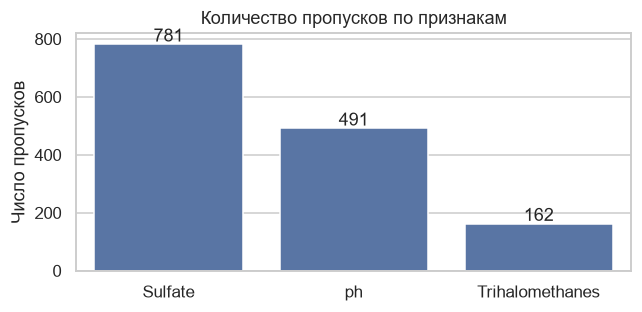

In [32]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Пропуски по признакам:")
print(pd.DataFrame({"пропусков": missing, "доля, %": (missing / len(df) * 100).round(1)}))

fig, ax = plt.subplots(figsize=(6, 3))
sns.barplot(x=missing.index, y=missing.values, ax=ax)
ax.set_title("Количество пропусков по признакам")
ax.set_ylabel("Число пропусков")
ax.set_xlabel("")
for i, v in enumerate(missing.values):
    ax.text(i, v + 10, str(v), ha="center")
plt.tight_layout()
plt.show()

                число  доля, %
0 — непитьевая   1998  61.0000
1 — питьевая     1278  39.0000


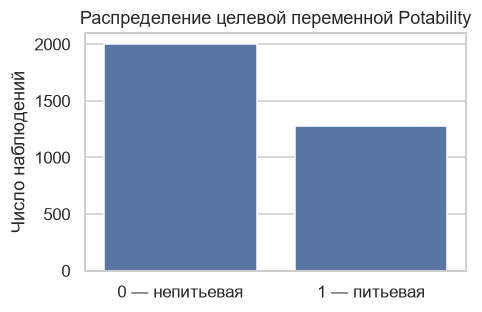

In [33]:
counts = df["Potability"].value_counts().sort_index()
print(pd.DataFrame({"число": counts.values, "доля, %": (counts / len(df) * 100).round(1).values},
                   index=["0 — непитьевая", "1 — питьевая"]))

fig, ax = plt.subplots(figsize=(4.5, 3))
sns.barplot(x=["0 — непитьевая", "1 — питьевая"], y=counts.values, ax=ax)
ax.set_title("Распределение целевой переменной Potability")
ax.set_ylabel("Число наблюдений")
plt.tight_layout()
plt.show()

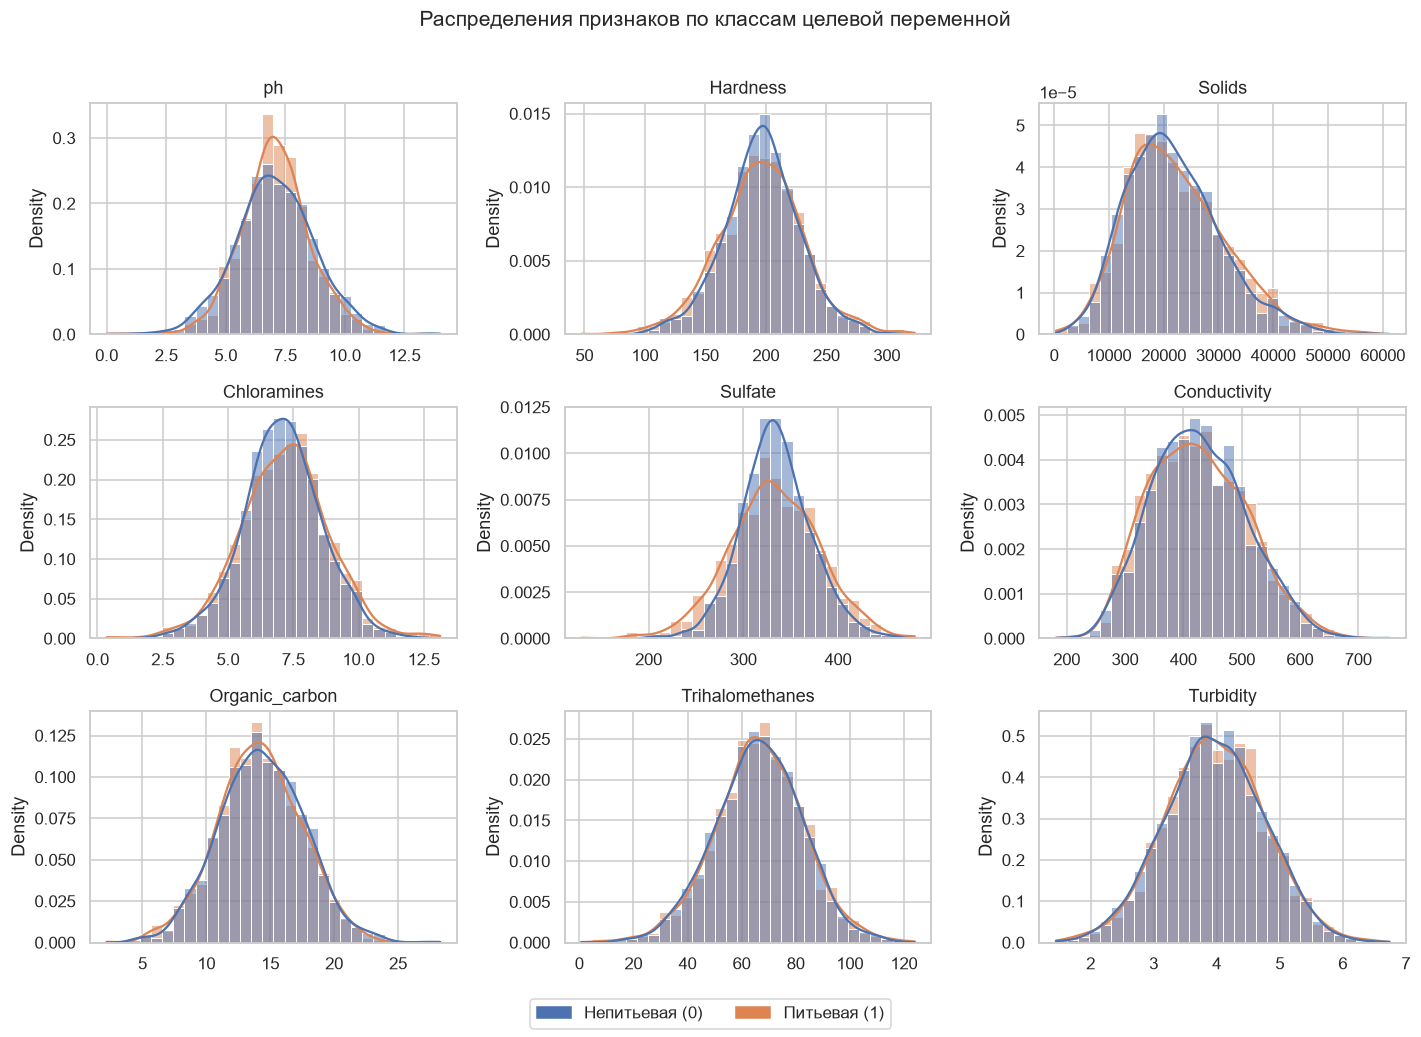

In [34]:
from matplotlib.patches import Patch

feature_names = [c for c in df.columns if c != "Potability"]
palette = {0: "#4c72b0", 1: "#dd8452"}

fig, axes = plt.subplots(3, 3, figsize=(13, 9.5))
for ax, col in zip(axes.ravel(), feature_names):
    sns.histplot(data=df, x=col, hue="Potability", palette=palette, bins=30, kde=True,
                 stat="density", common_norm=False, ax=ax, legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
handles = [Patch(color=palette[0], label="Непитьевая (0)"), Patch(color=palette[1], label="Питьевая (1)")]
fig.legend(handles=handles, loc="lower center", ncol=2, fontsize=11)
fig.suptitle("Распределения признаков по классам целевой переменной", fontsize=14)
plt.tight_layout(rect=[0, 0.04, 1, 0.97])
plt.show()

Выводы по первичному анализу

* Все 9 признаков — непрерывные числовые, категориальных признаков нет, поэтому кодирование не требуется.
* Пропуски есть в трёх признаках: Sulfate — 781 (23,8 %), ph — 491 (15,0 %), Trihalomethanes — 162 (4,9 %).
* Классы умеренно несбалансированы: 61,0 % непитьевых и 39,0 % питьевых.
* Признаки имеют разный масштаб (Solids — в десятках тысяч, Turbidity — единицы), поэтому стандартизация обязательна.
* Распределения большинства признаков близки к колоколообразным, Solids скошен вправо. Граничные значения ph (0 и 14) — крайние точки шкалы; выбросы не удалялись.
* Гистограммы питьевой и непитьевой воды почти совпадают.

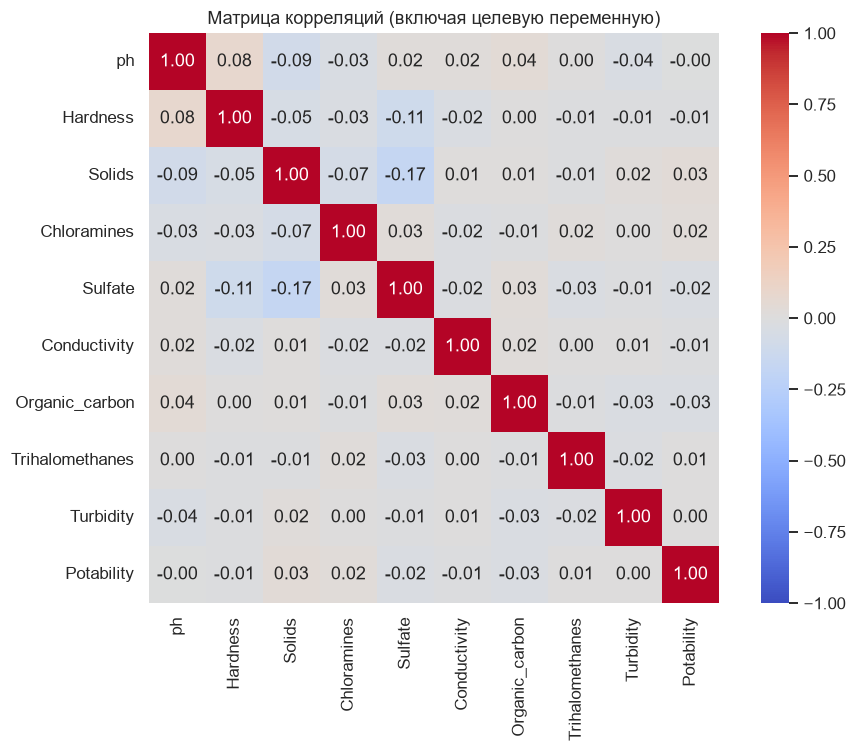

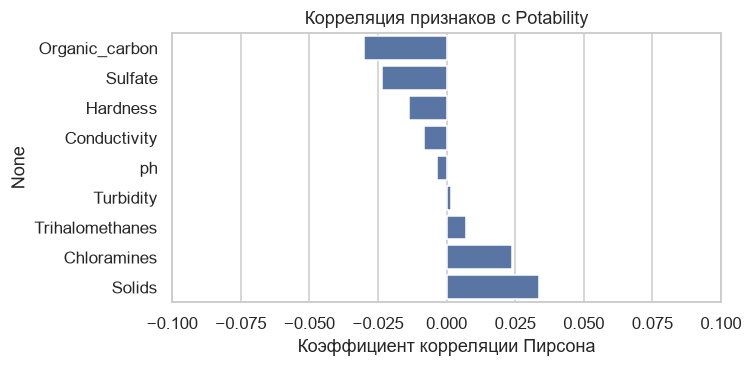

Максимальная |корреляция| признака с целевой переменной: 0.034 (Solids)


In [35]:
corr_all = df.corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_all, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Матрица корреляций (включая целевую переменную)")
plt.tight_layout()
plt.show()

corr_target = corr_all["Potability"].drop("Potability").sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=corr_target.values, y=corr_target.index, ax=ax)
ax.set_title("Корреляция признаков с Potability")
ax.set_xlabel("Коэффициент корреляции Пирсона")
ax.set_xlim(-0.1, 0.1)
plt.tight_layout()
plt.show()
print("Максимальная |корреляция| признака с целевой переменной: "
      f"{corr_target.abs().max():.3f} ({corr_target.abs().idxmax()})")

Корреляционный анализ. Корреляции признаков с целевой переменной малы: максимальная по модулю равна 0,034 (Solids). Признаки между собой также практически не связаны (подробнее — в п. 4.1). Следовательно, линейная зависимость Potability от признаков в данных почти отсутствует.

## 3. Подготовка данных

1. Пропуски. В соответствии с заданием строки с пропусками удаляются. Цена этого решения — потеря 38,6 % наблюдений (3276 -> 2011); доля класса 1 при этом почти не изменилась (0,390 -> 0,403).
2. Кодирование. Категориальных признаков нет — не требуется.
3. Разбиение. Выборка делится на обучающую (80 %) и тестовую (20 %) функцией train_test_split со стратификацией по классу (random_state=42): 1608 и 403 наблюдения, доля класса 1 в обеих — 0,40.
4. Стандартизация. Выполняется StandardScaler внутри Pipeline — среднее и дисперсия оцениваются только по обучающим данным.
5. Кросс-валидация. Используется стратифицированная 5-блочная схема. Гиперпараметры ($C$ или $\alpha$) подбираются по логарифмической сетке из 15 значений во внутреннем цикле (GridSearchCV), а качество оценивается во внешнем цикле (вложенная кросс-валидация), поэтому оценка не завышается подбором параметров.

In [36]:
n_before = len(df)
df_clean = df.dropna().reset_index(drop=True)
print(f"Строк до удаления пропусков:    {n_before}")
print(f"Строк после удаления пропусков: {len(df_clean)}  (потеряно {(1 - len(df_clean) / n_before) * 100:.1f}%)")
print("Доля класса 1 до / после: "
      f"{df['Potability'].mean():.3f} / {df_clean['Potability'].mean():.3f}")

X = df_clean.drop(columns="Potability")
y = df_clean["Potability"]

print("\nСтандартные отклонения признаков (до стандартизации):")
print(X.std().round(2))

Строк до удаления пропусков:    3276
Строк после удаления пропусков: 2011  (потеряно 38.6%)
Доля класса 1 до / после: 0.390 / 0.403

Стандартные отклонения признаков (до стандартизации):
ph                   1.5700
Hardness            32.6400
Solids            8642.2400
Chloramines          1.5800
Sulfate             41.2100
Conductivity        80.7100
Organic_carbon       3.3200
Trihalomethanes     16.0800
Turbidity            0.7800
dtype: float64


In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f"Обучающая выборка: {X_train.shape[0]} строк, доля класса 1 = {y_train.mean():.3f}")
print(f"Тестовая выборка:  {X_test.shape[0]} строк, доля класса 1 = {y_test.mean():.3f}")

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1)

Обучающая выборка: 1608 строк, доля класса 1 = 0.403
Тестовая выборка:  403 строк, доля класса 1 = 0.404


## 4. Ход работы

### 4.1. Корреляции между признаками и мультиколлинеарность

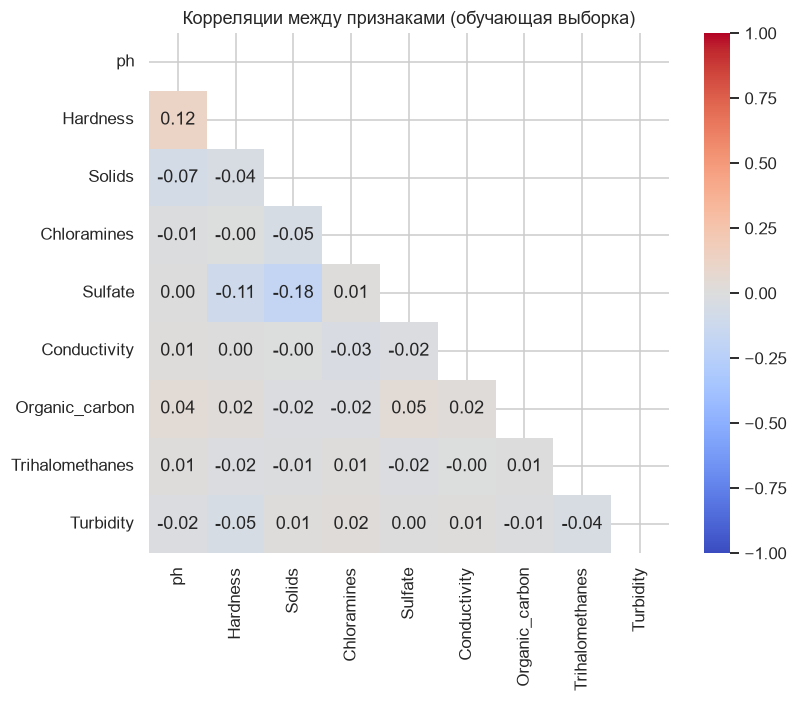

Максимальная попарная |корреляция| признаков: 0.178 (Sulfate — Solids)


In [38]:
corr_feat = X_train.corr()
mask = np.triu(np.ones_like(corr_feat, dtype=bool))

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr_feat, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Корреляции между признаками (обучающая выборка)")
plt.tight_layout()
plt.show()

off_diag = corr_feat.where(~mask).stack()
print(f"Максимальная попарная |корреляция| признаков: {off_diag.abs().max():.3f} "
      f"({' — '.join(off_diag.abs().idxmax())})")

                   VIF
ph              1.0210
Hardness        1.0320
Solids          1.0440
Chloramines     1.0050
Sulfate         1.0500
Conductivity    1.0020
Organic_carbon  1.0050
Trihalomethanes 1.0030
Turbidity       1.0050


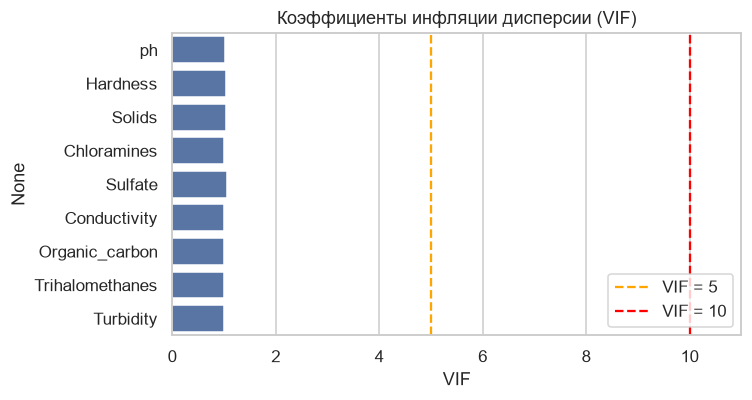

In [39]:
def compute_vif(features: pd.DataFrame) -> pd.Series:
    """VIF_j = 1 / (1 - R_j^2), где R_j^2 — коэффициент детерминации регрессии
    признака j на все остальные признаки (эквивалентно statsmodels.variance_inflation_factor)."""
    result = {}
    for col in features.columns:
        others = features.drop(columns=col)
        r2 = LinearRegression().fit(others, features[col]).score(others, features[col])
        result[col] = 1.0 / (1.0 - r2)
    return pd.Series(result, name="VIF")

vif = compute_vif(X_train)
print(vif.round(3).to_frame())

fig, ax = plt.subplots(figsize=(7, 3.8))
sns.barplot(x=vif.values, y=vif.index, ax=ax)
ax.axvline(5, color="orange", ls="--", label="VIF = 5")
ax.axvline(10, color="red", ls="--", label="VIF = 10")
ax.set_xlim(0, 11)
ax.set_xlabel("VIF")
ax.set_title("Коэффициенты инфляции дисперсии (VIF)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Вывод. Максимальная попарная корреляция признаков — 0,178 (Sulfate — Solids), значения VIF лежат в диапазоне 1,002–1,050 — на порядок ниже порога 5. Мультиколлинеарности в данных нетЖ, следовательно применять PCA нет смысла (проверяется в п. 4.5–4.7).

### 4.2. Метрики и протокол оценки

Ниже определены функции расчёта метрик и оценки моделей. Для каждой модели считаются:

* CV-оценка — среднее ± стандартное отклонение по 5 внешним блокам (вложенная кросс-валидация на обучающей выборке);
* Test-оценка — финальная модель, обученная на всей обучающей выборке, проверяется на отложенной тестовой (403 наблюдения).

Поскольку тестовая выборка небольшая, CV-оценке следует доверять больше: на 403 наблюдениях метрики имеют заметный случайный разброс.

Как читать метрики. $R^2=0$ означает, что модель не лучше прогноза средним значением целевой переменной, $R^2<0$ — хуже него. При доле класса 1 около 0,40 такой прогноз даёт $\text{RMSE}=\sqrt{p(1-p)}\approx 0{,}49$.

In [40]:
def mape_pos(y_true, y_pred):
    """MAPE по объектам класса 1.
    Для класса 0 знаменатель |y_true| равен нулю, поэтому MAPE там не определён."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    m = y_true == 1
    return np.mean(np.abs((y_true[m] - y_pred[m]) / y_true[m]))


def compute_scores(y_true, score):
    """Метрики для непрерывного прогноза `score` (вероятность класса 1 или выход линейной модели)."""
    y_true = np.asarray(y_true)
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, score)),
        "R2": r2_score(y_true, score),
        "MAPE": mape_pos(y_true, score),
    }


def predict_score(model, features):
    """Вероятность класса 1 для классификаторов, прямой прогноз — для регрессоров."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(features)[:, 1]
    return model.predict(features)


def make_logreg(kind):
    """Логистическая регрессия: без штрафа / L1 (Lasso) / L2 (Ridge).
    Учтено изменение API в scikit-learn 1.8 (параметр penalty объявлен устаревшим)."""
    new_api = tuple(int(p) for p in sklearn.__version__.split(".")[:2]) >= (1, 8)
    if new_api:
        return {"none": LogisticRegression(C=np.inf, max_iter=5000),
                "l1": LogisticRegression(l1_ratio=1, solver="liblinear"),
                "l2": LogisticRegression(l1_ratio=0)}[kind]
    return {"none": LogisticRegression(penalty=None, max_iter=5000),
            "l1": LogisticRegression(penalty="l1", solver="liblinear"),
            "l2": LogisticRegression(penalty="l2")}[kind]


def run_model(pipe, grid=None, scoring=None, data=None):
    """Оценка модели двумя способами:
    1) вложенная кросс-валидация на обучающей выборке (5 блоков; гиперпараметры подбираются
       во внутреннем цикле, поэтому оценка не завышена);
    2) финальное обучение на всей обучающей выборке и проверка на тестовой.
    Возвращает словарь метрик и обученную модель."""
    Xtr, ytr, Xte, yte = data if data is not None else (X_train, y_train, X_test, y_test)
    est = GridSearchCV(pipe, grid, cv=inner_cv, scoring=scoring) if grid else pipe

    cv_rows = []
    for tr, va in outer_cv.split(Xtr, ytr):
        m = clone(est).fit(Xtr.iloc[tr], ytr.iloc[tr])
        cv_rows.append(compute_scores(ytr.iloc[va], predict_score(m, Xtr.iloc[va])))
    cv_mean = pd.DataFrame(cv_rows).mean()
    cv_std = pd.DataFrame(cv_rows).std()

    final = clone(est).fit(Xtr, ytr)
    test = compute_scores(yte, predict_score(final, Xte))
    best = final.best_params_ if grid else {}
    return {"cv": cv_mean, "cv_std": cv_std, "test": pd.Series(test),
            "best": best, "model": final.best_estimator_ if grid else final}


LOGIT_GRID = {"m__C": np.logspace(-3, 2, 15)}
LASSO_GRID = {"m__alpha": np.logspace(-4, 0, 15)}
RIDGE_GRID = {"m__alpha": np.logspace(-2, 4, 15)}

In [41]:
results = {}


### 4.3. Логистическая регрессия на исходных признаках

In [42]:
logit_specs = {
    "Логистическая (без штрафа)": (make_logreg("none"), None),
    "Логистическая + L1 (Lasso)": (make_logreg("l1"), LOGIT_GRID),
    "Логистическая + L2 (Ridge)": (make_logreg("l2"), LOGIT_GRID),
}

for name, (clf, grid) in logit_specs.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("m", clf)])
    results[("Исходные", name)] = run_model(pipe, grid, scoring="neg_log_loss")
    print(f"{name:30s} лучшие гиперпараметры: {results[('Исходные', name)]['best']}")

Логистическая (без штрафа)     лучшие гиперпараметры: {}
Логистическая + L1 (Lasso)     лучшие гиперпараметры: {'m__C': np.float64(0.0610540229658533)}
Логистическая + L2 (Ridge)     лучшие гиперпараметры: {'m__C': np.float64(0.001)}


In [43]:
def summary_table(space, names):
    """Сводная таблица: метрики CV (среднее ± std) и на тестовой выборке."""
    rows = []
    for n in names:
        r = results[(space, n)]
        row = {"Модель": n}
        for k in ["RMSE", "R2", "MAPE"]:
            row[f"CV {k}"] = f"{r['cv'][k]:.3f} ± {r['cv_std'][k]:.3f}"
        for k in ["RMSE", "R2", "MAPE"]:
            row[f"Test {k}"] = round(r["test"][k], 4)
        rows.append(row)
    return pd.DataFrame(rows).set_index("Модель")

logit_names = list(logit_specs)
summary_table("Исходные", logit_names).T

Модель,Логистическая (без штрафа),Логистическая + L1 (Lasso),Логистическая + L2 (Ridge)
CV RMSE,0.491 ± 0.001,0.491 ± 0.000,0.490 ± 0.000
CV R2,-0.002 ± 0.005,-0.001 ± 0.002,0.000 ± 0.001
CV MAPE,0.596 ± 0.001,0.581 ± 0.007,0.597 ± 0.000
Test RMSE,0.4921,0.4910,0.4910
Test R2,-0.0053,-0.0007,-0.0007
Test MAPE,0.5979,0.5874,0.5973


In [44]:
coef_tbl = pd.DataFrame({
    n: results[("Исходные", n)]["model"].named_steps["m"].coef_[0] for n in logit_names
}, index=X.columns)
print("Коэффициенты логистических моделей (признаки стандартизованы):")
display(coef_tbl.round(4))
print("Число коэффициентов, обнулённых L1-штрафом:",
      int((coef_tbl["Логистическая + L1 (Lasso)"] == 0).sum()), "из", len(coef_tbl))

Коэффициенты логистических моделей (признаки стандартизованы):


,Логистическая (без штрафа),Логистическая + L1 (Lasso),Логистическая + L2 (Ridge)
ph,0.0385,0.0000,0.0091
Hardness,-0.0147,0.0000,-0.0033
Solids,0.0851,0.0455,0.0244
Chloramines,0.0356,0.0000,0.0094
Sulfate,-0.0441,-0.0044,-0.0142
Conductivity,-0.0645,-0.0206,-0.0178
Organic_carbon,0.0262,0.0000,0.0065
Trihalomethanes,0.0037,0.0000,0.0009
Turbidity,0.0351,0.0000,0.0098


Число коэффициентов, обнулённых L1-штрафом: 6 из 9


Анализ результатов.

* Все три модели практически не отличаются друг от друга и от прогноза средним значением: CV-RMSE 0,490–0,491, CV-$R^2$ от −0,002 до 0,000 ($R^2\approx 0$ означает, что модель не лучше прогноза средним).
* Оптимальное $C$ для L2-модели оказалось на нижней границе сетки ($C=0{,}001$): кросс-валидация предпочитает максимально сжатую модель, то есть признаки не несут линейного сигнала.
* L1-штраф обнулил 6 из 9 коэффициентов, оставив Solids, Conductivity и с малым весом Sulfate. Но веса малы (≤ 0,05 при стандартизованных признаках), а CV-$R^2$ этой модели ($-0{,}001 \pm 0{,}002$) неотличим от нуля, поэтому считать эти признаки важными нельзя — это шум.
* Чуть меньший MAPE у L1-модели (0,581 против 0,597 у остальных моделей) не является улучшением: MAPE считается только по классу 1 и вознаграждает завышение вероятностей; RMSE и $R^2$ при этом не улучшились.

### 4.4. Линейная регрессия, Lasso и Ridge (целевая переменная 0/1)

In [45]:
linear_specs = {
    "Линейная (OLS)": (LinearRegression(), None, None),
    "Lasso": (Lasso(max_iter=20000), LASSO_GRID, "neg_root_mean_squared_error"),
    "Ridge": (Ridge(), RIDGE_GRID, "neg_root_mean_squared_error"),
}

for name, (reg, grid, scoring) in linear_specs.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("m", reg)])
    results[("Исходные", name)] = run_model(pipe, grid, scoring)
    print(f"{name:16s} лучшие гиперпараметры: {results[('Исходные', name)]['best']}")

linear_names = list(linear_specs)
summary_table("Исходные", linear_names).T

Линейная (OLS)   лучшие гиперпараметры: {}
Lasso            лучшие гиперпараметры: {'m__alpha': np.float64(0.03727593720314938)}
Ridge            лучшие гиперпараметры: {'m__alpha': np.float64(10000.0)}


Модель,Линейная (OLS),Lasso,Ridge
CV RMSE,0.491 ± 0.001,0.491 ± 0.000,0.490 ± 0.000
CV R2,-0.002 ± 0.005,-0.000 ± 0.000,0.000 ± 0.001
CV MAPE,0.596 ± 0.001,0.597 ± 0.000,0.597 ± 0.000
Test RMSE,0.4922,0.4908,0.4909
Test R2,-0.0057,-0.0000,-0.0003
Test MAPE,0.5980,0.5970,0.5972


Анализ результатов. RMSE 0,490–0,491, $R^2$ в пределах ±0,006 от нуля. Поведение регуляризации: оптимальный $\alpha$ для Lasso ($\approx 0{,}037$) обнуляет все коэффициенты, и модель вырождается в константу ($R^2=0$), а для Ridge $\alpha$ выбран на верхней границе сетки ($10^4$). Обычная МНК-модель, наоборот, чуть хуже константы на тесте ($R^2=-0{,}0057$) — это небольшое переобучение на шуме. Кроме того, линейная модель может выдавать вероятности вне отрезка [0, 1], поэтому для бинарной цели логистическая регрессия методологически предпочтительнее.

### 4.5. Снижение размерности методом главных компонент

PCA применяется к стандартизованным признакам и обучается только на обучающей выборке.

In [46]:
scaler_full = StandardScaler().fit(X_train)
Z_train = scaler_full.transform(X_train)

pca_full = PCA(random_state=RANDOM_STATE).fit(Z_train)
eigenvalues = pca_full.explained_variance_
ratio = pca_full.explained_variance_ratio_
cum_ratio = np.cumsum(ratio)

pca_table = pd.DataFrame({
    "Собственное значение": eigenvalues,
    "Доля дисперсии": ratio,
    "Накопленная доля": cum_ratio,
}, index=[f"PC{i}" for i in range(1, len(ratio) + 1)])
print(pca_table.round(4))

n_85 = int(np.argmax(cum_ratio >= 0.85) + 1)
print(f"Компонент для накопленной доли ≥ 85%:  {n_85}")

     Собственное значение  Доля дисперсии  Накопленная доля
PC1                1.2130          0.1347            0.1347
PC2                1.1830          0.1314            0.2661
PC3                1.0487          0.1165            0.3825
PC4                1.0296          0.1143            0.4968
PC5                0.9896          0.1099            0.6067
PC6                0.9719          0.1079            0.7147
PC7                0.9418          0.1046            0.8192
PC8                0.8652          0.0961            0.9153
PC9                0.7627          0.0847            1.0000
Компонент для накопленной доли ≥ 85%:  8


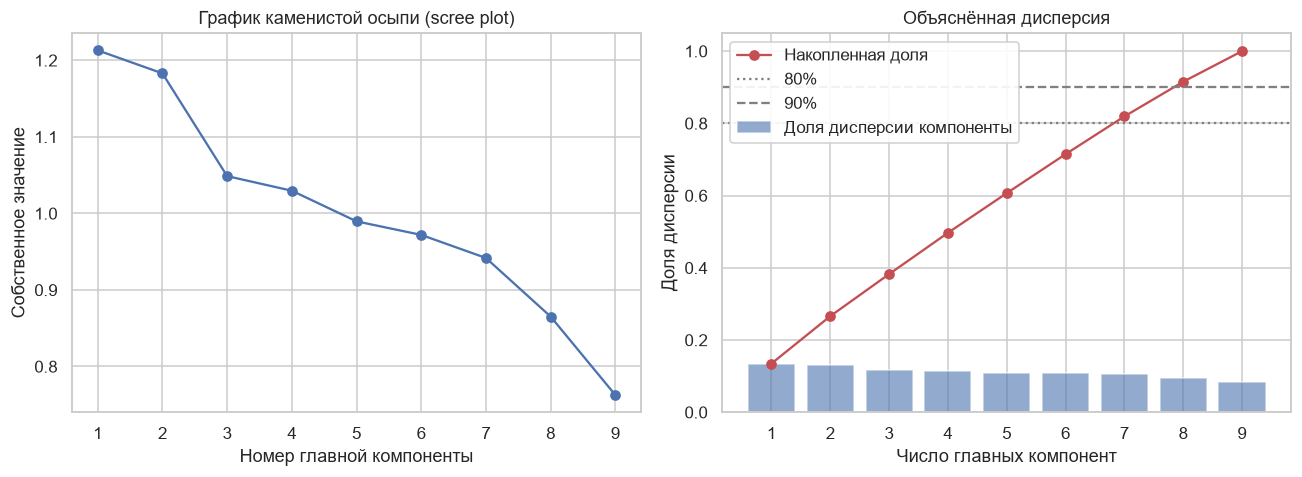

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
idx = np.arange(1, len(eigenvalues) + 1)

axes[0].plot(idx, eigenvalues, "o-")
axes[0].set_title("График каменистой осыпи (scree plot)")
axes[0].set_xlabel("Номер главной компоненты")
axes[0].set_ylabel("Собственное значение")
axes[0].set_xticks(idx)

axes[1].bar(idx, ratio, alpha=0.6, label="Доля дисперсии компоненты")
axes[1].plot(idx, cum_ratio, "ro-", label="Накопленная доля")
axes[1].axhline(0.80, color="gray", ls=":", label="80%")
axes[1].axhline(0.90, color="gray", ls="--", label="90%")
axes[1].set_title("Объяснённая дисперсия")
axes[1].set_xlabel("Число главных компонент")
axes[1].set_ylabel("Доля дисперсии")
axes[1].set_xticks(idx)
axes[1].legend(loc="upper left", framealpha=0.9)
plt.tight_layout()
plt.show()

Выбрано главных компонент: 8 (сохранено 91.5% дисперсии)


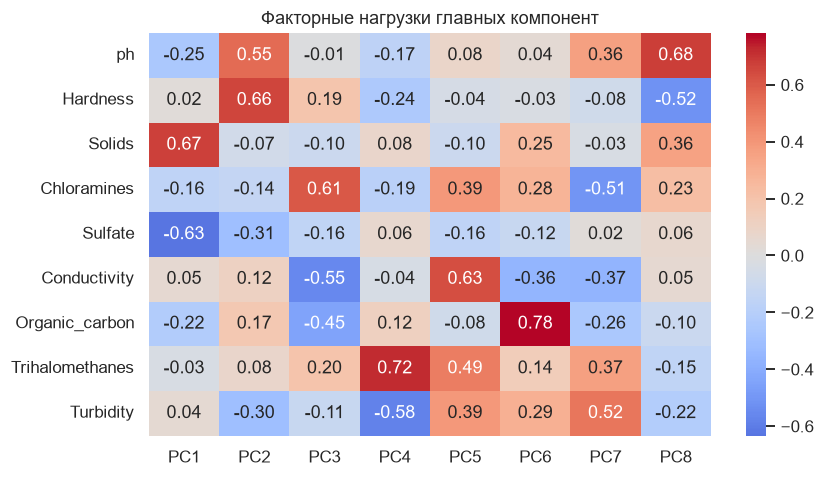

Максимальная |корреляция| между компонентами: 0.0
VIF главных компонент: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


In [48]:
N_COMP = 0.85

pca = PCA(n_components=N_COMP, random_state=RANDOM_STATE).fit(Z_train)
k = pca.n_components_
print(f"Выбрано главных компонент: {k} (сохранено {pca.explained_variance_ratio_.sum() * 100:.1f}% дисперсии)")

loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=[f"PC{i}" for i in range(1, k + 1)])
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Факторные нагрузки главных компонент")
plt.tight_layout()
plt.show()

pcs = pd.DataFrame(pca.transform(Z_train), columns=loadings.columns)
print("Максимальная |корреляция| между компонентами:",
      round(float(np.abs(pcs.corr().values - np.eye(k)).max()), 6))
print("VIF главных компонент:", compute_vif(pcs).round(3).tolist())

Анализ результатов.

* Собственные значения меняются от 1,21 до 0,76. Первая компонента объясняет лишь 13,5 % дисперсии (для 9 полностью независимых признаков было бы 11,1 %).
* Порог накопленной дисперсии 85 % (середина диапазона 80–90 %) требует 8 компонент из 9 (91,5 %). Для дальнейших экспериментов выбрано 8 компонент.
* Это следствие слабой корреляции признаков: дисперсия распределена между компонентами почти равномерно, поэтому сжать данные без потери информации нельзя.
* Факторные нагрузки. Компоненты представляют собой смеси нескольких признаков, а не отдельные признаки. Наиболее заметная структура — у первой компоненты: она противопоставляет Solids (+0,67) и Sulfate (−0,63), то есть именно ту пару признаков, у которой максимальная корреляция (0,178). У остальных компонент нагрузки распределены между несколькими признаками без явной доминанты.
* Проверка. Главные компоненты не коррелированы между собой (максимальная корреляция равна 0), VIF каждой компоненты равен 1.

### 4.6. Регрессионные модели на главных компонентах

Те же шесть моделей обучаются заново, но вместо исходных признаков на вход подаются 8 главных компонент (стандартизация -> PCA -> модель, всё внутри Pipeline).

In [49]:
def pca_pipe(estimator):
    return Pipeline([("scaler", StandardScaler()),
                     ("pca", PCA(n_components=N_COMP, random_state=RANDOM_STATE)),
                     ("m", estimator)])

for name, (clf, grid) in logit_specs.items():
    results[("PCA", name)] = run_model(pca_pipe(clone(clf)), grid, scoring="neg_log_loss")
for name, (reg, grid, scoring) in linear_specs.items():
    results[("PCA", name)] = run_model(pca_pipe(clone(reg)), grid, scoring)

print("Логистические модели на главных компонентах:")
display(summary_table("PCA", logit_names).T)
print("Линейные модели (цель 0/1) на главных компонентах:")
display(summary_table("PCA", linear_names).T)

Логистические модели на главных компонентах:


Модель,Логистическая (без штрафа),Логистическая + L1 (Lasso),Логистическая + L2 (Ridge)
CV RMSE,0.491 ± 0.001,0.491 ± 0.000,0.490 ± 0.000
CV R2,-0.002 ± 0.005,-0.001 ± 0.001,0.000 ± 0.001
CV MAPE,0.596 ± 0.001,0.584 ± 0.001,0.597 ± 0.000
Test RMSE,0.4923,0.4918,0.4910
Test R2,-0.0060,-0.0041,-0.0009
Test MAPE,0.5980,0.5880,0.5974


Линейные модели (цель 0/1) на главных компонентах:


Модель,Линейная (OLS),Lasso,Ridge
CV RMSE,0.491 ± 0.001,0.490 ± 0.000,0.490 ± 0.000
CV R2,-0.002 ± 0.005,-0.000 ± 0.000,0.000 ± 0.001
CV MAPE,0.596 ± 0.001,0.597 ± 0.000,0.597 ± 0.000
Test RMSE,0.4924,0.4908,0.4909
Test R2,-0.0065,-0.0000,-0.0004
Test MAPE,0.5981,0.5970,0.5972


### 4.7. Сравнение моделей на исходных признаках и на главных компонентах

In [50]:
rows = []
for fam, names in [("Логистическая", logit_names), ("Линейная (цель 0/1)", linear_names)]:
    for n in names:
        for space in ["Исходные", "PCA"]:
            r = results[(space, n)]
            rows.append({"Семейство": fam, "Модель": n, "Признаки": space,
                         **{f"CV {k}": r["cv"][k] for k in ["RMSE", "R2", "MAPE"]},
                         **{f"Test {k}": r["test"][k] for k in ["RMSE", "R2", "MAPE"]}})
cmp_df = pd.DataFrame(rows)
display(cmp_df.set_index(["Семейство", "Модель", "Признаки"]).round(4))

delta = (cmp_df[cmp_df["Признаки"] == "PCA"].set_index(["Семейство", "Модель"]).drop(columns="Признаки")
         - cmp_df[cmp_df["Признаки"] == "Исходные"].set_index(["Семейство", "Модель"]).drop(columns="Признаки"))
print("Изменение метрик (PCA − исходные признаки):")
display(delta.round(4))

CV RMSE   CV R2  CV MAPE  Test RMSE  Test R2  Test MAPE
Семейство           Модель                     Признаки                                                         
Логистическая       Логистическая (без штрафа) Исходные   0.4910 -0.0019   0.5963     0.4921  -0.0053     0.5979
                                               PCA        0.4909 -0.0016   0.5961     0.4923  -0.0060     0.5980
                    Логистическая + L1 (Lasso) Исходные   0.4908 -0.0012   0.5809     0.4910  -0.0007     0.5874
                                               PCA        0.4907 -0.0008   0.5842     0.4918  -0.0041     0.5880
                    Логистическая + L2 (Ridge) Исходные   0.4904  0.0003   0.5969     0.4910  -0.0007     0.5973
                                               PCA        0.4904  0.0003   0.5968     0.4910  -0.0009     0.5974
Линейная (цель 0/1) Линейная (OLS)             Исходные   0.4911 -0.0024   0.5963     0.4922  -0.0057     0.5980
                                               PCA        0.4910 -0.0020   0.5962     0.4924  -0.0065     0.5981
                    Lasso                      Исходные   0.4905 -0.0002   0.5970     0.4908  -0.0000     0.5970
                                               PCA        0.4905 -0.0000   0.5970     0.4908  -0.0000     0.5970
                    Ridge                      Исходные   0.4905  0.0002   0.5969     0.4909  -0.0003     0.5972
                                               PCA        0.4904  0.0002   0.5969     0.4909  -0.0004     0.5972

Изменение метрик (PCA − исходные признаки):


CV RMSE  CV R2  CV MAPE  Test RMSE  Test R2  Test MAPE
Семейство           Модель                                                                            
Логистическая       Логистическая (без штрафа)  -0.0001 0.0004  -0.0002     0.0002  -0.0007     0.0001
                    Логистическая + L1 (Lasso)  -0.0001 0.0004   0.0033     0.0008  -0.0034     0.0006
                    Логистическая + L2 (Ridge)  -0.0000 0.0000  -0.0000     0.0000  -0.0002     0.0000
Линейная (цель 0/1) Линейная (OLS)              -0.0001 0.0003  -0.0002     0.0002  -0.0008     0.0001
                    Lasso                       -0.0000 0.0001   0.0001     0.0000   0.0000     0.0000
                    Ridge                       -0.0000 0.0000  -0.0000     0.0000  -0.0001     0.0000

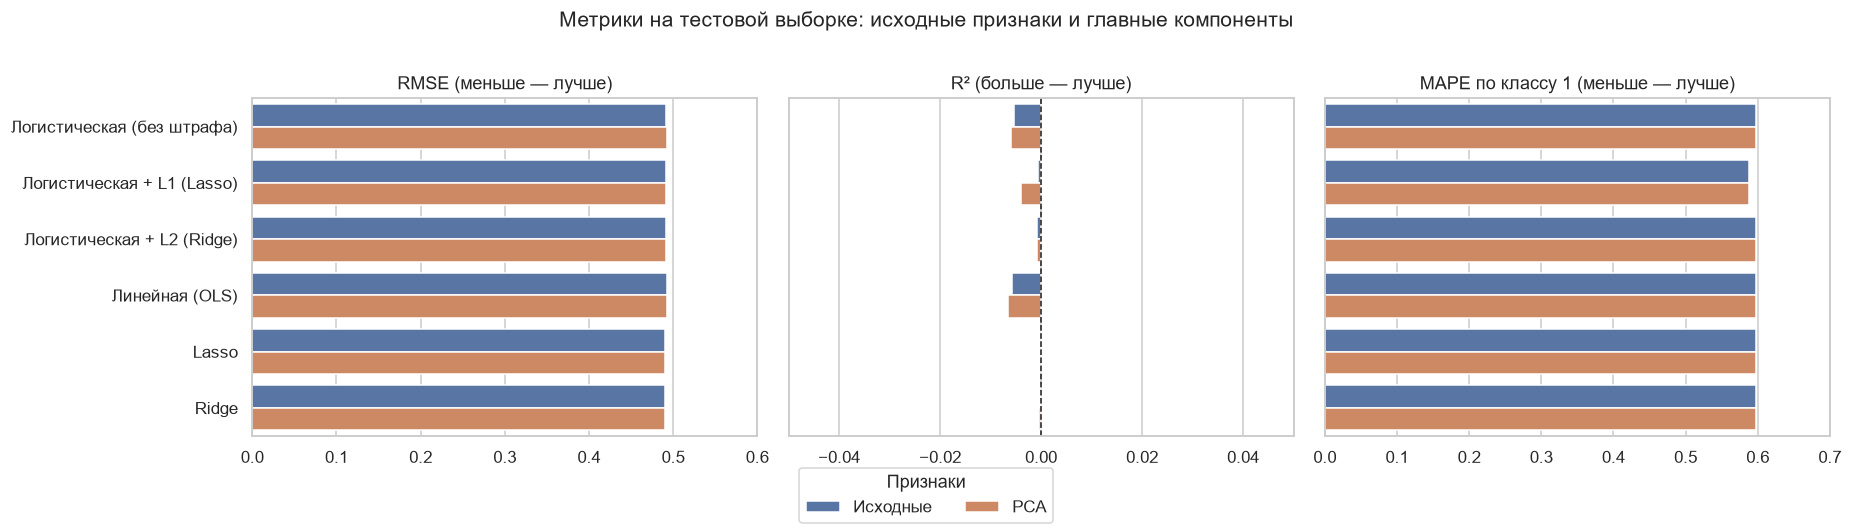

In [51]:
metrics = [("RMSE", "RMSE (меньше — лучше)"), ("R2", "R² (больше — лучше)"),
           ("MAPE", "MAPE по классу 1 (меньше — лучше)")]

XLIMS = {"RMSE": (0, 0.6), "R2": (-0.05, 0.05), "MAPE": (0, 0.7)}   # шкалы не обрезаны
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for ax, (m, title) in zip(axes, metrics):
    sns.barplot(data=cmp_df, y="Модель", x=f"Test {m}", hue="Признаки", ax=ax)
    ax.set_title(title)
    ax.set_ylabel("")
    ax.set_xlabel("")
    ax.set_xlim(*XLIMS[m])
axes[1].axvline(0, color="k", ls="--", lw=1)   # R² = 0: прогноз средним значением цели
handles, labels = axes[0].get_legend_handles_labels()
for ax in axes:
    if ax.get_legend() is not None:
        ax.get_legend().remove()
fig.legend(handles, labels, title="Признаки", loc="lower center", ncol=2)
fig.suptitle("Метрики на тестовой выборке: исходные признаки и главные компоненты", fontsize=14)
plt.tight_layout(rect=[0, 0.08, 1, 0.97])
plt.show()

Анализ результатов.

* Разницы практически нет. При переходе к главным компонентам RMSE изменяется не более чем на 0,0008, $R^2$ — не более чем на 0,0034 (тест), а CV-$R^2$ — не более чем на 0,0004. Все эти изменения лежат внутри разброса оценок между блоками кросс-валидации (стандартное отклонение CV-$R^2$ достигает 0,005).
* Наибольшее отличие — у логистической модели с L1-штрафом (на тесте $R^2$ −0,0007 -> −0,0041, RMSE 0,4910 -> 0,4918). Такое различие на 403 наблюдениях — шум: оба значения практически нулевые, а по кросс-валидации разница $R^2$ составляет всего 0,0004.
* Объяснение: PCA — ортогональный поворот осей; модель без регуляризации на всех компонентах даёт те же предсказания, что и на исходных признаках, а штраф L2 (Ridge) поворотом не меняется. Единственное отличие создаёт отбрасывание девятой компоненты (8,5 % дисперсии), которая, судя по неизменности метрик, не несёт полезного сигнала. L1-штраф зависит от выбора осей, но на данных без сигнала это тоже ни на что не влияет.
* Выигрыша PCA не даёт, потому что мультиколлинеарности не было (п. 4.1). Ни число обусловленности, ни устойчивость коэффициентов здесь не были проблемой.

Ниже показано, как меняется качество в зависимости от числа компонент.

CV R² по числу компонент: [-0.001, -0.0013, -0.003, -0.0035, -0.004, -0.0029, -0.0016, -0.0016, -0.0019]
CV R² на исходных признаках: -0.0019


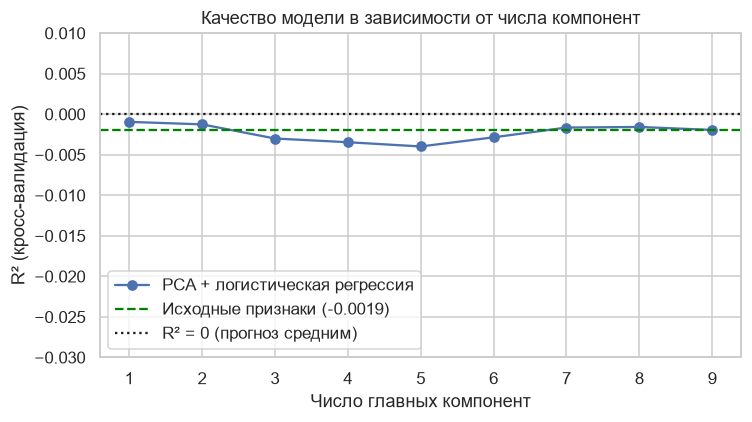

In [52]:
def cv_r2(pipe):
    """Средний по блокам R² (кросс-валидация на обучающей выборке)."""
    scores = []
    for tr, va in outer_cv.split(X_train, y_train):
        m = clone(pipe).fit(X_train.iloc[tr], y_train.iloc[tr])
        scores.append(r2_score(y_train.iloc[va], predict_score(m, X_train.iloc[va])))
    return float(np.mean(scores))

ks = list(range(1, X.shape[1] + 1))
r2_by_k = [cv_r2(Pipeline([("scaler", StandardScaler()),
                           ("pca", PCA(n_components=kk, random_state=RANDOM_STATE)),
                           ("m", make_logreg("l2"))])) for kk in ks]
r2_orig = cv_r2(Pipeline([("scaler", StandardScaler()), ("m", make_logreg("l2"))]))
print("CV R² по числу компонент:", [round(v, 4) for v in r2_by_k])
print("CV R² на исходных признаках:", round(r2_orig, 4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ks, r2_by_k, "o-", label="PCA + логистическая регрессия")
ax.axhline(r2_orig, color="green", ls="--", label=f"Исходные признаки ({r2_orig:.4f})")
ax.axhline(0, color="k", ls=":", label="R² = 0 (прогноз средним)")
ax.set_xlabel("Число главных компонент")
ax.set_ylabel("R² (кросс-валидация)")
ax.set_title("Качество модели в зависимости от числа компонент")
ax.set_xticks(ks)
ax.set_ylim(-0.03, 0.01)
ax.legend()
plt.tight_layout()
plt.show()

Во всём диапазоне $k$ от 1 до 9 CV-$R^2$ остаётся практически нулевым (от −0,004 до −0,001) и ни разу не становится положительным, то есть выбор числа компонент не позволяет превзойти прогноз средним значением. При $k=9$ значение совпадает с исходными признаками (−0,0019) — это полный поворот осей, как и следует из теории. Подбор числа компонент ничего не улучшает.


### 4.8. Анализ причин погрешности и способы повышения точности

Почему линейные модели работают плохо:
1. Нет линейного сигнала. Корреляции признаков с целью ≤ 0,034; модели не лучше прогноза средним значением. Предположительная причина — несоответствие класса модели структуре данных.
2. Потеря данных. Удаление пропусков сократило выборку на 38,6 %, что ухудшает оценку и может сместить распределение.
3. Малая тестовая выборка (403 наблюдения): одиночная тестовая оценка заметно колеблется, поэтому различия между моделями в тысячных долях RMSE и $R^2$ статистически не значимы.
4. Несоответствие метрик задаче. RMSE, $R^2$ и MAPE предназначены для регрессии. Для бинарной цели MAPE неопределён на классе 0, а $R^2$ и RMSE по вероятностям сообщают лишь то, что модель не лучше прогноза средним значением.
5. Происхождение метки. В описании датасета не сказано, как именно определялась пригодность воды, поэтому неизвестно, насколько она вообще определяется измеренными показателями.

Что можно сделать для повышения точности:

* Регуляризация (L1, L2, подбор $C$/$\alpha$ по сетке) и PCA с разным числом компонент существенного улучшения не дали. Попробовать нелинейную модель.

## 5. Заключение

1. Датасет Water Potability содержит 3276 наблюдений и 9 числовых признаков; целевая переменная бинарная (39 % питьевых), поэтому основной моделью выбрана логистическая регрессия (без штрафа, L1 и L2); дополнительно построены линейная регрессия, Lasso и Ridge на кодировке 0/1. После удаления пропусков (−38,6 %) осталось 2011 наблюдений.
2. Мультиколлинеарность отсутствует: максимальная попарная корреляция признаков 0,178, VIF от 1,002 до 1,050.
3. Линейные модели практически не лучше прогноза средним значением: RMSE ≈ 0,49, $R^2\approx 0$ (от −0,006 до 0,000 на тесте). Регуляризация не помогла (логистическая модель с L1-штрафом обнуляет 6 из 9 коэффициентов, линейный Lasso — все).
4. PCA не улучшил и не ухудшил качество: по шкале каменистой осыпи выраженного «локтя» нет, для сохранения 85 % дисперсии требуется 8 компонент из 9; все метрики на главных компонентах отличаются от исходных в пределах случайного разброса (RMSE ±0,0008, $R^2$ ±0,0034). Это закономерно: PCA — поворот осей, а коррелированности признаков, которую нужно было устранять, в данных нет.
5. Главная причина низкого качества — отсутствие линейной зависимости цели от признаков: корреляции не превышают 0,034, а модели не лучше прогноза средним. Вероятно, зависимость (если она есть) нелинейная или определяется взаимодействием признаков; проверка нелинейных моделей в работе не проводилась и остаётся направлением для дальнейшего исследования, а подбор регуляризации или числа главных компонент ситуацию не меняет.
6. Методический вывод: для бинарной цели метрики RMSE, $R^2$ и MAPE малоинформативны (MAPE неопределён на классе 0, а $R^2\approx 0$ лишь показывает отсутствие выигрыша относительно среднего), а стандартизацию и PCA необходимо обучать только на обучающих данных, чтобы избежать утечки.

## 6. Список источников

1. Алетдинова А. А. Системы искусственного интеллекта : учебное пособие / А. А. Алетдинова, М. Г. Гриф. — Новосибирск : Изд-во НГТУ, 2023. — 73 с.
2. Алетдинова А. А. Интеллектуальный анализ больших данных : учебное пособие / А. А. Алетдинова, М. Ш. Муртазина. — Новосибирск : Изд-во НГТУ, 2023. — 66 с.
3. Алетдинова А. А. Компьютерные методы обработки данных : учеб. пособие / А. А. Алетдинова, М. Ш. Муртазина. — Новосибирск : Изд-во НГТУ, 2021. — 64 с.
4. Гриф М. Г. Интеллектуальные системы и технологии : учебное пособие / М. Г. Гриф. — Новосибирск : Изд-во НГТУ, 2021. — 72 с.
5. Лю Ю. Х. Обучение с подкреплением на PyTorch: сборник рецептов / пер. с англ. А. А. Слинкина. — М. : ДМК Пресс, 2020. — 282 с. : ил.
6. Лорьер Ж. Л. Системы искусственного интеллекта = Intelligence Artificielle / Ж. Л. Лорьер ; пер., ред. пер. В. Л. Стефанюк. — Москва : Мир, 1991. — 568 с. : ил.
7. Ротштейн А. П. Интеллектуальные технологии идентификации: нечеткая логика, генетические алгоритмы, нейронные сети / А. П. Ротштейн. — Винница : УНИВЕРСУМ-Винница, 1999. — 320 с.
8. Замятин А. В. и др. Введение в интеллектуальный анализ данных : учебное пособие. — Томск : Издательский Дом ТГУ, 2016. — 120 с.
9. Kaggle. Water Quality and Potability (water_potability.csv). — URL: https://www.kaggle.com/datasets/adityakadiwal/water-potability
10. Pedregosa F. et al. Scikit-learn: Machine Learning in Python // Journal of Machine Learning Research. — 2011. — Vol. 12. — P. 2825–2830. — URL: https://scikit-learn.org/stable/
11. Документация библиотек pandas (https://pandas.pydata.org/docs/), NumPy (https://numpy.org/doc/), Matplotlib (https://matplotlib.org/stable/) и seaborn (https://seaborn.pydata.org/).
12. Материалы курса: «Машинное обучение, регрессия и факторный анализ» (PDF), «Машинное обучение» (PDF), презентации «Регрессия» и «Факторный анализ».